In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import math
import pandas as pd
import numpy as np


import warnings
warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_understanding/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_raw.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    exit(1)



✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_understanding/' pronta.
✅ Dataset preparato caricato: 114000 righe, 21 colonne.


In [2]:
df.head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
8,8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,...,-8.700,1,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic
9,9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,205594,False,0.442,0.6320,...,-6.770,1,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic


In [3]:
df.info(verbose=True, memory_usage='deep', show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [4]:
print(df.isna().sum())

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [5]:
df.dropna(axis=0, inplace=True)

In [6]:
df.describe(include='all').T.style.background_gradient(cmap='viridis')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,113999.000000,nan,nan,nan,56999.421925,32909.243463,0.000000,28499.500000,56999.000000,85499.500000,113999.000000
track_id,113999,89740,6S3JlDAGk3uu3NtZbPnuhS,9,nan,nan,nan,nan,nan,nan,nan
artists,113999,31437,The Beatles,279,nan,nan,nan,nan,nan,nan,nan
album_name,113999,46589,Alternative Christmas 2022,195,nan,nan,nan,nan,nan,nan,nan
track_name,113999,73608,Run Rudolph Run,151,nan,nan,nan,nan,nan,nan,nan
popularity,113999.000000,nan,nan,nan,33.238827,22.304959,0.000000,17.000000,35.000000,50.000000,100.000000
duration_ms,113999.000000,nan,nan,nan,228031.153387,107296.057716,8586.000000,174066.000000,212906.000000,261506.000000,5237295.000000
explicit,113999,2,False,104252,nan,nan,nan,nan,nan,nan,nan
danceability,113999.000000,nan,nan,nan,0.566801,0.173543,0.000000,0.456000,0.580000,0.695000,0.985000
energy,113999.000000,nan,nan,nan,0.641383,0.251530,0.000000,0.472000,0.685000,0.854000,1.000000


In [7]:
df.drop(columns=['Unnamed: 0', 'track_id'], axis=1, inplace=True)

In [8]:
# creo una colonna dalla tonalità completa
# New keymode column: "C major", "A minor", etc.
keys = ['C','C#','D','Eb','E','F','F#','G','Ab','A','Bb','B']
df['keymode'] = df['key'].map(dict(enumerate(keys))).str.cat(
    df['mode'].map({0: 'minor', 1: 'major'}), sep=' '
)

# Eliminiamo le colonne key e mode
df.drop(columns=['key', 'mode'], axis=1, inplace=True)


In [9]:
# converto la colonna numerica duration_ms in minuti
df['duration_mins'] = df['duration_ms'] / 60000

# elimino la colonna duration_ms per evitare ovvie ridondanze e leakages
df.drop(columns=['duration_ms'], axis=1, inplace=True)

In [10]:
df['explicit'] = df['explicit'].astype(int)

In [11]:
# Rinomino la colonna track_genre in genres
df.rename(columns={'track_genre': 'genres'}, inplace=True)

In [12]:
# Vediamo quanti generi esistono e come si distribuiscono
print(df['genres'].unique())

['acoustic' 'afrobeat' 'alt-rock' 'alternative' 'ambient' 'anime'
 'black-metal' 'bluegrass' 'blues' 'brazil' 'breakbeat' 'british'
 'cantopop' 'chicago-house' 'children' 'chill' 'classical' 'club' 'comedy'
 'country' 'dance' 'dancehall' 'death-metal' 'deep-house' 'detroit-techno'
 'disco' 'disney' 'drum-and-bass' 'dub' 'dubstep' 'edm' 'electro'
 'electronic' 'emo' 'folk' 'forro' 'french' 'funk' 'garage' 'german'
 'gospel' 'goth' 'grindcore' 'groove' 'grunge' 'guitar' 'happy'
 'hard-rock' 'hardcore' 'hardstyle' 'heavy-metal' 'hip-hop' 'honky-tonk'
 'house' 'idm' 'indian' 'indie-pop' 'indie' 'industrial' 'iranian'
 'j-dance' 'j-idol' 'j-pop' 'j-rock' 'jazz' 'k-pop' 'kids' 'latin'
 'latino' 'malay' 'mandopop' 'metal' 'metalcore' 'minimal-techno' 'mpb'
 'new-age' 'opera' 'pagode' 'party' 'piano' 'pop-film' 'pop' 'power-pop'
 'progressive-house' 'psych-rock' 'punk-rock' 'punk' 'r-n-b' 'reggae'
 'reggaeton' 'rock-n-roll' 'rock' 'rockabilly' 'romance' 'sad' 'salsa'
 'samba' 'sertanejo' 'show

### MAPPING DI 114 GENERI IN 10 MACRO-CATEGORIE

In [13]:
# Super-categorie (10 max)
CATS = [
    "Pop & Indie",
    "Rock & Alternative",
    "Metal & Hardcore",
    "Hip-Hop & R&B",
    "Electronic & Dance",
    "Latin & Brazilian",
    "World & Regional",
    "Jazz/Soul/Funk/Blues",
    "Country/Folk & Songwriter",
    "Classical/Ambient & Stage"
]

GENRE_TO_10 = {
    # Pop & Indie
    "pop":"Pop & Indie","indie":"Pop & Indie","indie-pop":"Pop & Indie",
    "power-pop":"Pop & Indie","synth-pop":"Pop & Indie","romance":"Pop & Indie",
    "happy":"Pop & Indie","sad":"Pop & Indie",
    # Rock & Alternative
    "rock":"Rock & Alternative","alt-rock":"Rock & Alternative","alternative":"Rock & Alternative",
    "rock-n-roll":"Rock & Alternative","rockabilly":"Rock & Alternative",
    "punk":"Rock & Alternative","punk-rock":"Rock & Alternative","grunge":"Rock & Alternative",
    "psych-rock":"Rock & Alternative","emo":"Rock & Alternative","goth":"Rock & Alternative",
    "hard-rock":"Rock & Alternative",
    # Metal & Hardcore
    "metal":"Metal & Hardcore","heavy-metal":"Metal & Hardcore","black-metal":"Metal & Hardcore",
    "death-metal":"Metal & Hardcore","metalcore":"Metal & Hardcore","grindcore":"Metal & Hardcore",
    "hardcore":"Metal & Hardcore",
    # Hip-Hop & R&B
    "hip-hop":"Hip-Hop & R&B","r-n-b":"Hip-Hop & R&B",
    # Electronic & Dance
    "electronic":"Electronic & Dance","edm":"Electronic & Dance","electro":"Electronic & Dance",
    "house":"Electronic & Dance","deep-house":"Electronic & Dance","progressive-house":"Electronic & Dance",
    "chicago-house":"Electronic & Dance","detroit-techno":"Electronic & Dance",
    "techno":"Electronic & Dance","minimal-techno":"Electronic & Dance",
    "trance":"Electronic & Dance","hardstyle":"Electronic & Dance",
    "drum-and-bass":"Electronic & Dance","dubstep":"Electronic & Dance",
    "garage":"Electronic & Dance","breakbeat":"Electronic & Dance","trip-hop":"Electronic & Dance",
    "idm":"Electronic & Dance","disco":"Electronic & Dance","dance":"Electronic & Dance",
    "club":"Electronic & Dance","party":"Electronic & Dance","industrial":"Electronic & Dance",
    # Latin & Brazilian
    "latin":"Latin & Brazilian","latino":"Latin & Brazilian","brazil":"Latin & Brazilian",
    "forro":"Latin & Brazilian","mpb":"Latin & Brazilian","pagode":"Latin & Brazilian",
    "samba":"Latin & Brazilian","salsa":"Latin & Brazilian","sertanejo":"Latin & Brazilian",
    "tango":"Latin & Brazilian","reggaeton":"Latin & Brazilian",
    # World & Regional (non-Latin + reggae area)
    "world-music":"World & Regional","afrobeat":"World & Regional",
    "k-pop":"World & Regional","j-pop":"World & Regional","j-rock":"World & Regional",
    "j-idol":"World & Regional","j-dance":"World & Regional",
    "cantopop":"World & Regional","mandopop":"World & Regional",
    "indian":"World & Regional","iranian":"World & Regional","turkish":"World & Regional",
    "malay":"World & Regional","anime":"World & Regional",
    "british":"World & Regional","french":"World & Regional","german":"World & Regional",
    "swedish":"World & Regional","spanish":"World & Regional",
    "reggae":"World & Regional","ska":"World & Regional","dub":"World & Regional","dancehall":"World & Regional",
    # Jazz/Soul/Funk/Blues
    "jazz":"Jazz/Soul/Funk/Blues","blues":"Jazz/Soul/Funk/Blues","soul":"Jazz/Soul/Funk/Blues",
    "funk":"Jazz/Soul/Funk/Blues","groove":"Jazz/Soul/Funk/Blues","gospel":"Jazz/Soul/Funk/Blues",
    # Country/Folk & Songwriter
    "country":"Country/Folk & Songwriter","folk":"Country/Folk & Songwriter",
    "bluegrass":"Country/Folk & Songwriter","honky-tonk":"Country/Folk & Songwriter",
    "singer-songwriter":"Country/Folk & Songwriter","songwriter":"Country/Folk & Songwriter",
    "acoustic":"Country/Folk & Songwriter","guitar":"Country/Folk & Songwriter",
    # Classical/Ambient & Stage/Film
    "classical":"Classical/Ambient & Stage","opera":"Classical/Ambient & Stage",
    "new-age":"Classical/Ambient & Stage","ambient":"Classical/Ambient & Stage","chill":"Classical/Ambient & Stage",
    "sleep":"Classical/Ambient & Stage","study":"Classical/Ambient & Stage",
    "piano":"Classical/Ambient & Stage","show-tunes":"Classical/Ambient & Stage",
    "disney":"Classical/Ambient & Stage","comedy":"Classical/Ambient & Stage","children":"Classical/Ambient & Stage",
    "pop-film":"Classical/Ambient & Stage",
}

# Applica mappa (assume la colonna si chiami 'genre')
df["genres_10"] = (
    df["genres"].str.lower().map(GENRE_TO_10).fillna("World & Regional")
)


In [15]:
# Convertiamo a tipo category per pura semantica
df["genres_10"] = df["genres_10"].astype("category")

In [16]:
df.head()

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres,keymode,duration_mins,genres_10
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,C# minor,3.844433,Country/Folk & Songwriter
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,C# major,2.493500,Country/Folk & Songwriter
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,C major,3.513767,Country/Folk & Songwriter
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,C major,3.365550,Country/Folk & Songwriter
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,D major,3.314217,Country/Folk & Songwriter


#### distribuziuoni variabili numeriche

le colonne numeriche sono: ['popularity', 'explicit', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'duration_mins']


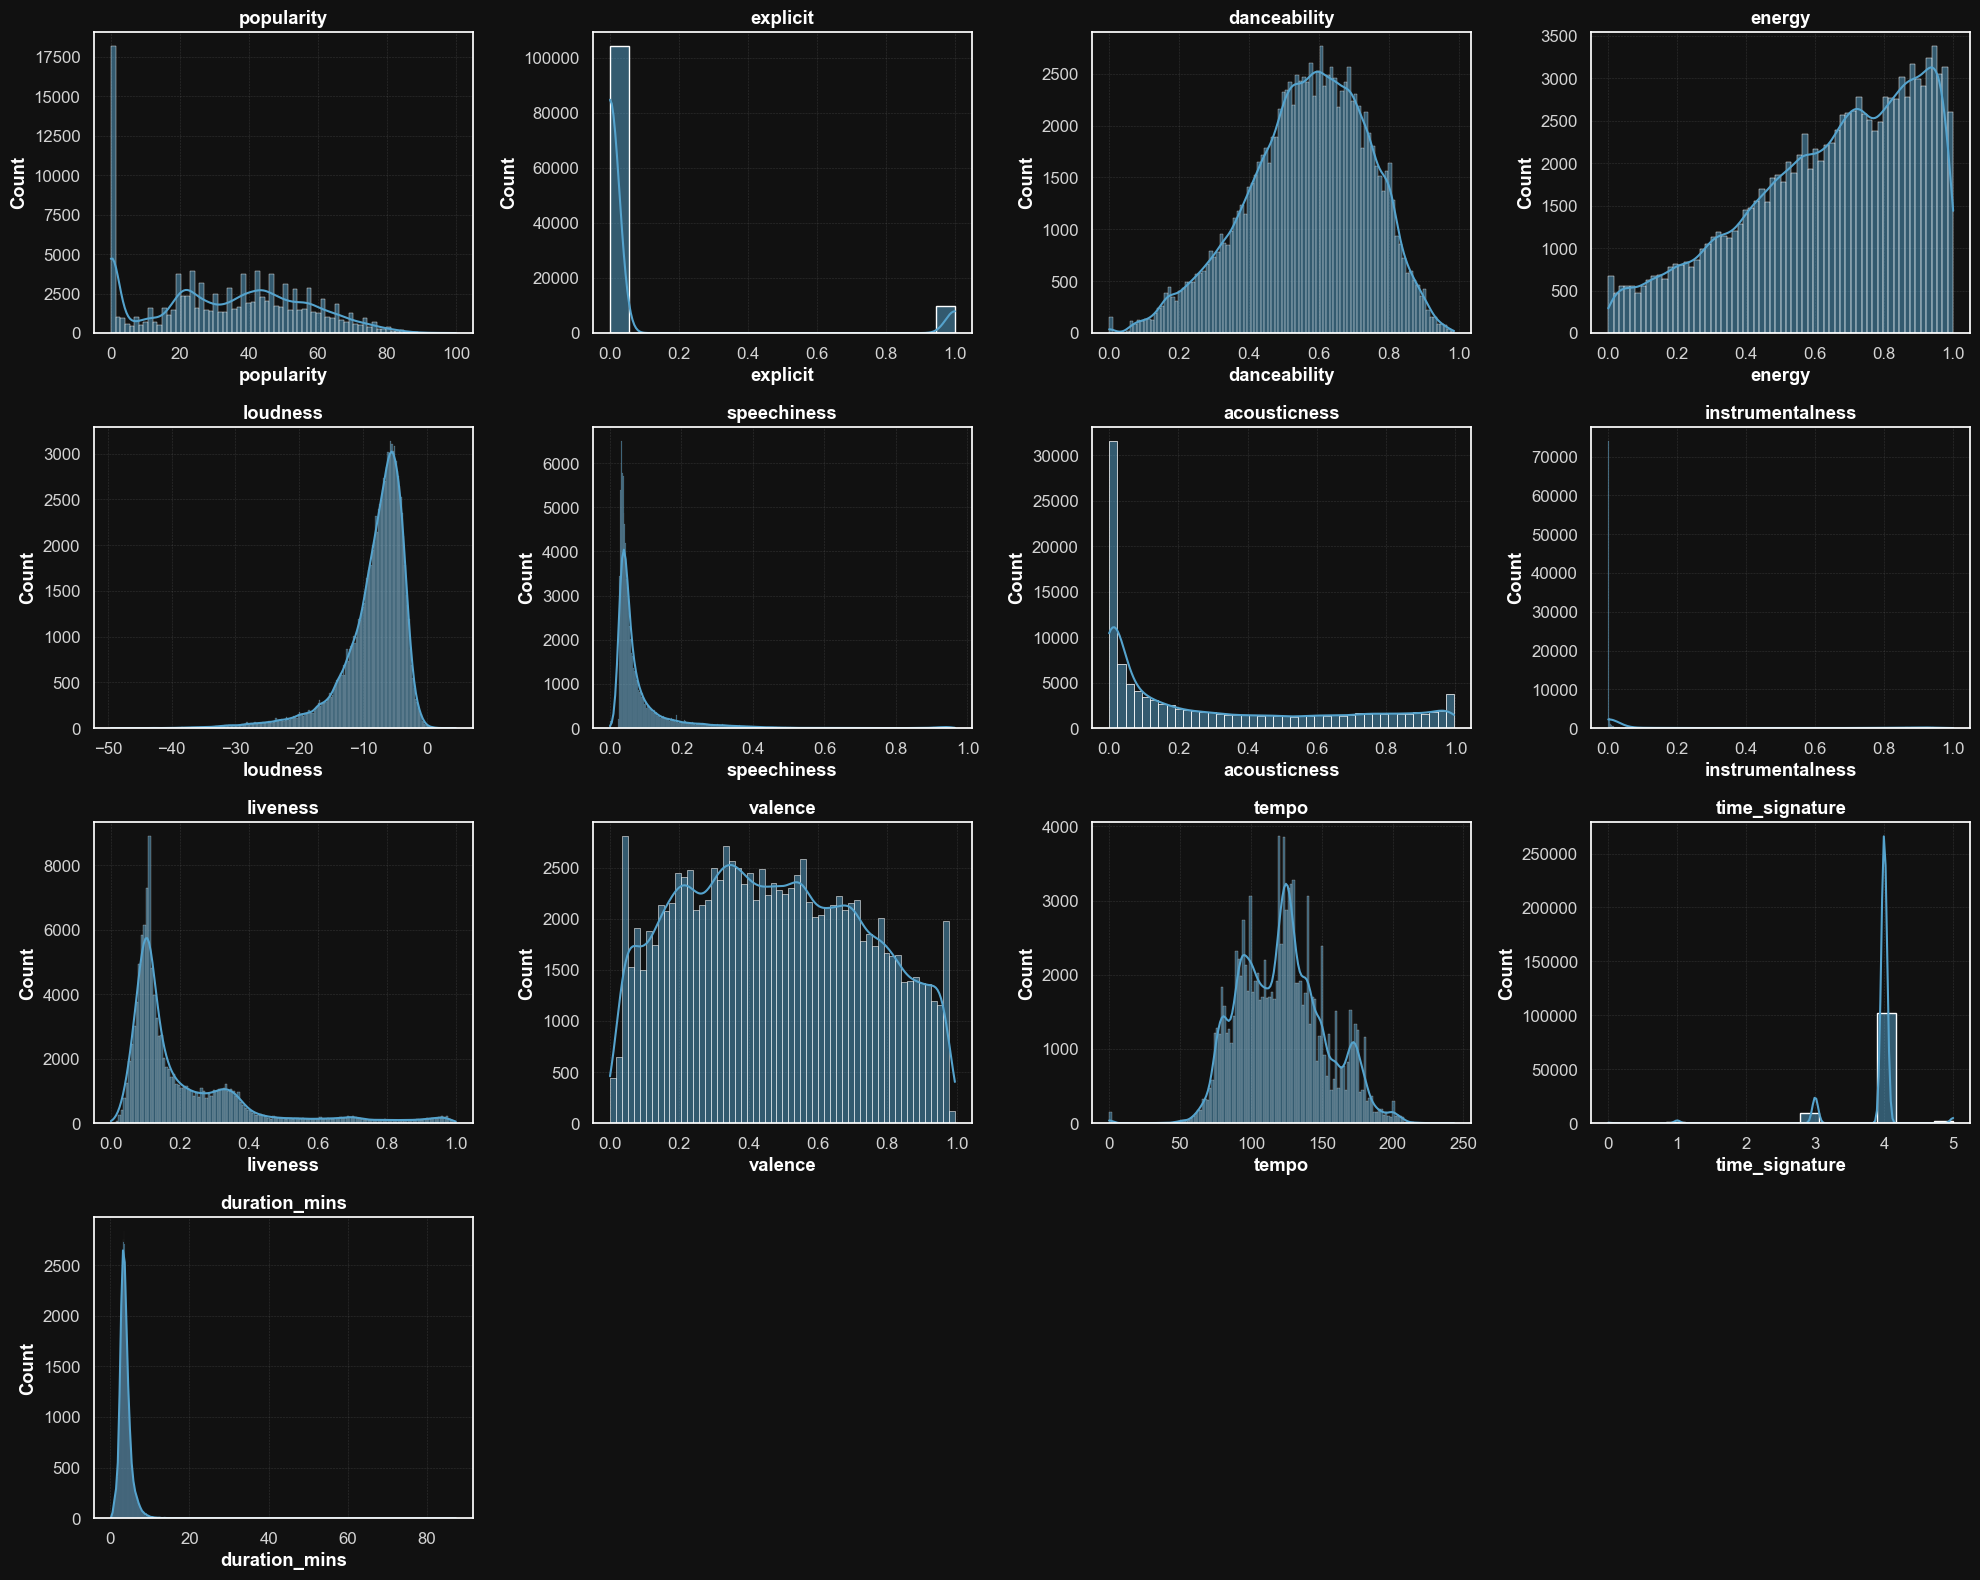

In [17]:
# Seleziono le variabili numeriche
numeric_columns = df.select_dtypes(include=[np.number], exclude=['object']).columns.tolist()
print(f"le colonne numeriche sono: {numeric_columns}")


n_cols = 4
n_vars = len(numeric_columns)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

# spegne eventuali subplot vuoti
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



#### Correlazioni variabili numeriche, indici di Pearson e Spearman

<Axes: title={'center': 'Spearman monotonic correlations'}>

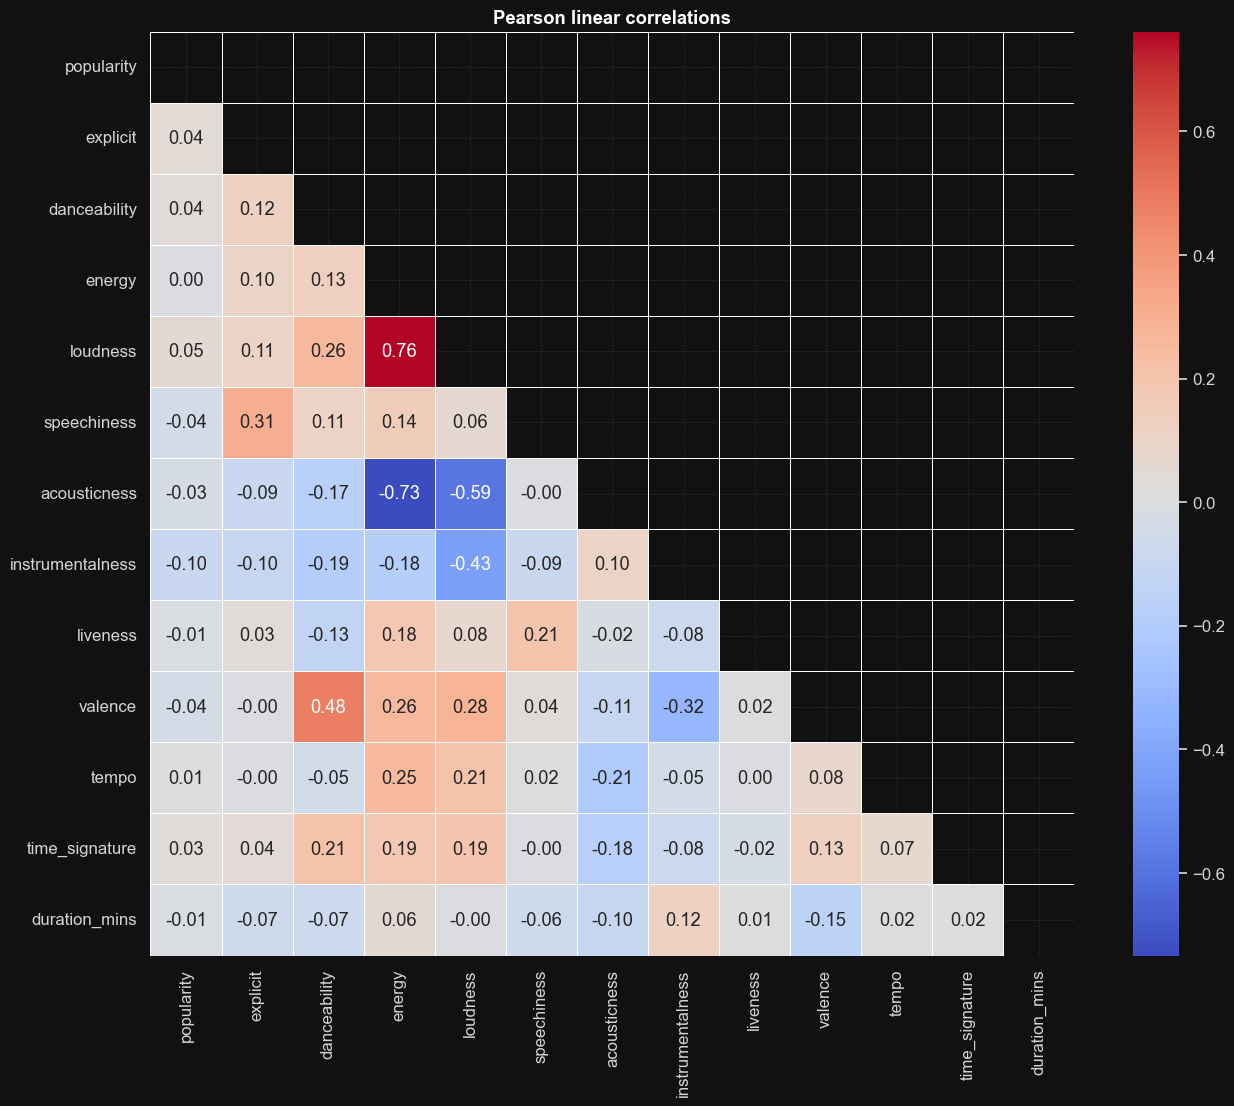

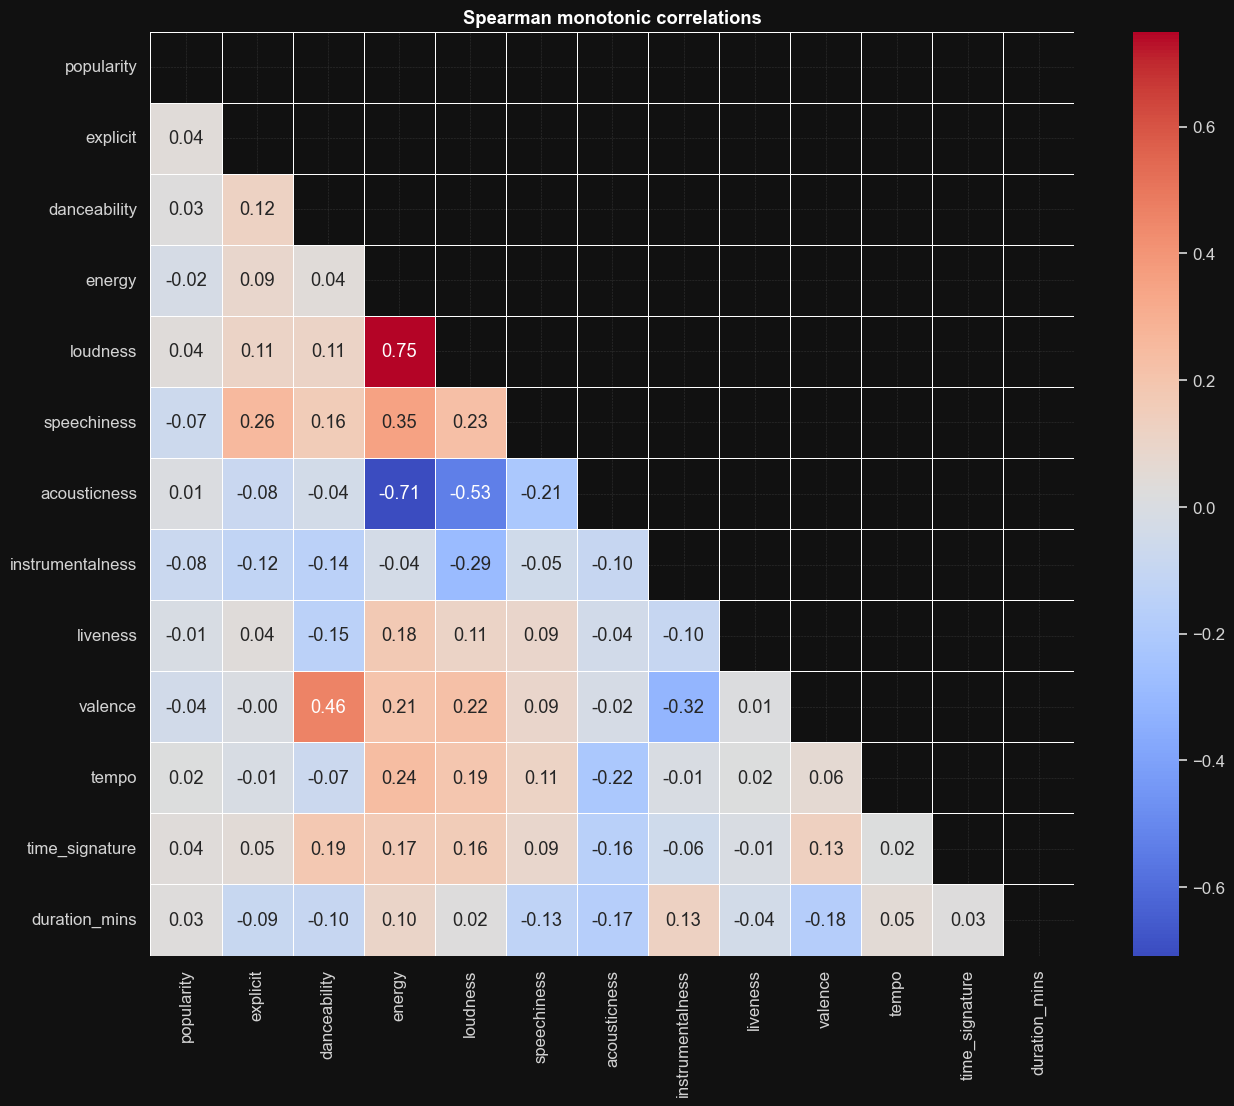

In [18]:
pearson_matrix  = df[numeric_columns].corr(method='pearson')
pearson_mask = np.triu(np.ones_like(pearson_matrix, dtype=bool))  # nasconde diag+upper

spearman_matrix = df[numeric_columns].corr(method='spearman')
spearman_mask = np.triu(np.ones_like(pearson_matrix, dtype=bool))  # nasconde diag+upper

plt.figure(figsize=(15, 12))
plt.title("Pearson linear correlations")
sns.heatmap(pearson_matrix, mask=pearson_mask, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, linecolor='white', square=True)

plt.figure(figsize=(15, 12))
plt.title("Spearman monotonic correlations")
sns.heatmap(spearman_matrix, mask=spearman_mask, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, linecolor='white', square=True)


In [19]:
df

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres,keymode,duration_mins,genres_10
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic,C# minor,3.844433,Country/Folk & Songwriter
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic,C# major,2.493500,Country/Folk & Songwriter
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic,C major,3.513767,Country/Folk & Songwriter
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic,C major,3.365550,Country/Folk & Songwriter
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic,D major,3.314217,Country/Folk & Songwriter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,0,0.172,0.2350,-16.393,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music,F major,6.416650,World & Regional
113996,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,0,0.174,0.1170,-18.318,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music,C minor,6.416667,World & Regional
113997,Cesária Evora,Best Of,Miss Perfumado,22,0,0.629,0.3290,-10.895,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music,C minor,4.524433,World & Regional
113998,Michael W. Smith,Change Your World,Friends,41,0,0.587,0.5060,-10.889,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music,G major,4.731550,World & Regional


#### Distribuzione variabili categoriche

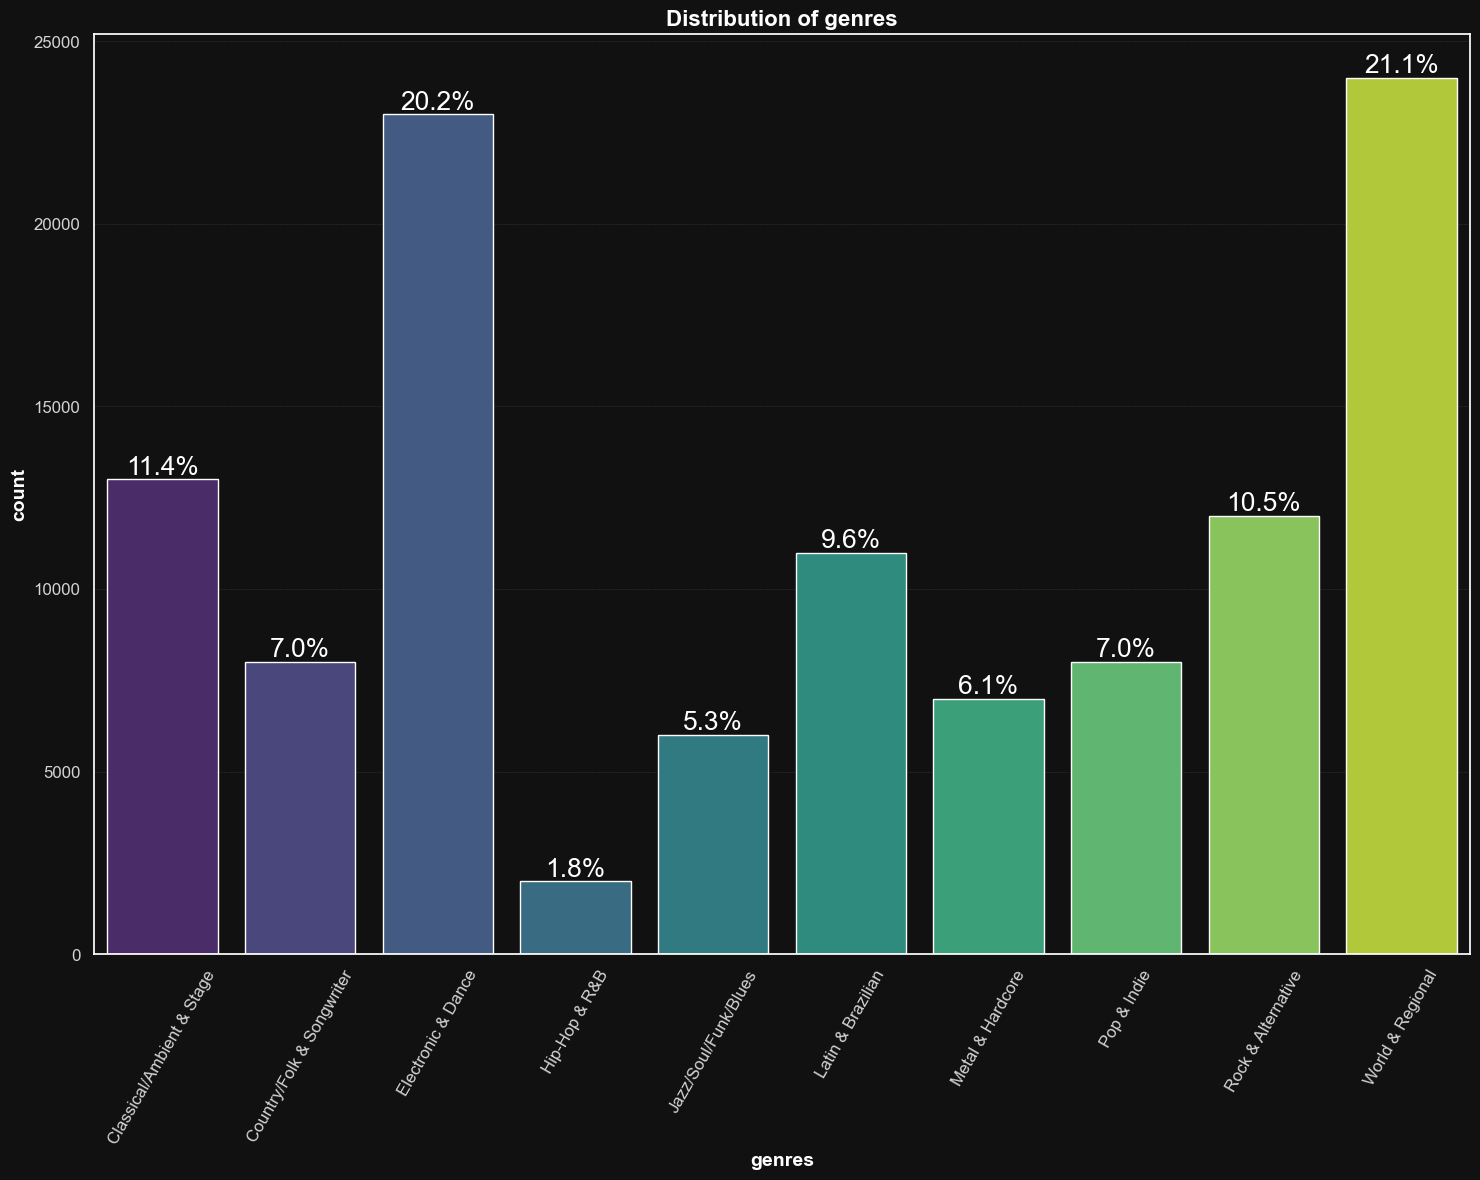

In [20]:
metadata_columns = ['artists', 'album_name', 'track_name', 'genres']
categorical_columns = ['keymode', 'genres_10']

plt.figure(figsize=(15,12))
ax = sns.countplot(data=df, x='genres_10', palette='viridis')  # opz.: order=df['genres_10'].value_counts().index
plt.title("Distribution of genres", fontsize=16, fontweight='bold')
plt.xlabel("genres", fontsize=14)
plt.ylabel("count", fontsize=14)
plt.xticks(rotation=60)

total = df['genres_10'].notna().sum()
for p in ax.patches:
    h = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, h, f'{h/total:.1%}',
            ha='center', va='bottom', fontsize=19)

plt.tight_layout()
plt.show()


In [22]:
df.head()

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres,keymode,duration_mins,genres_10
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,C# minor,3.844433,Country/Folk & Songwriter
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,C# major,2.493500,Country/Folk & Songwriter
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,C major,3.513767,Country/Folk & Songwriter
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,C major,3.365550,Country/Folk & Songwriter
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,D major,3.314217,Country/Folk & Songwriter


In [23]:
#Salvataggio Dataset
df.to_csv("Dataset/spotify_prepared.csv", index=False)